In [ ]:

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for name in uploaded:
    print(name)


KeyboardInterrupt: 

In [ ]:

import os

for name in [
    "measurements_5bus_multi.csv",
    "measurements_9bus_multi.csv",
    "measurements_14bus_multi.csv"
]:
    print(name, "FOUND" if os.path.exists(name) else "NOT FOUND")


measurements_5bus_multi.csv FOUND
measurements_9bus_multi.csv FOUND
measurements_14bus_multi.csv FOUND


In [ ]:

import pandas as pd
import numpy as np
import os

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

for topology, filename in files.items():
    print("\n" + "=" * 50)
    print(topology, "DATASET")

    df = pd.read_csv(filename)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist()[:15], "...")

    label_candidates = [
        c for c in df.columns
        if c.lower() in ["label_multi", "label", "target"]
    ]

    if label_candidates:
        label_col = label_candidates[0]
        print("Label column:", label_col)
        print("Label counts:")
        print(df[label_col].value_counts(dropna=False).sort_index())
    else:
        print("WARNING: No obvious label column found.")

    print("Duplicate rows:", df.duplicated().sum())
    print("Missing cells:", df.isna().sum().sum())
    print("Infinite numeric values:",
          np.isinf(df.select_dtypes(include=np.number)).sum().sum())



5-bus DATASET
Shape: (151031, 38)
Columns: ['Timestamp', 'Flow_1_2_t-0', 'Flow_1_3_t-0', 'Flow_2_4_t-0', 'Flow_3_5_t-0', 'Flow_4_5_t-0', 'Inj_2_t-0', 'Inj_3_t-0', 'Inj_4_t-0', 'Inj_5_t-0', 'Flow_1_2_t-1', 'Flow_1_3_t-1', 'Flow_2_4_t-1', 'Flow_3_5_t-1', 'Flow_4_5_t-1'] ...
Label column: label_multi
Label counts:
label_multi
0.0     60316
1.0      3021
2.0      3029
3.0      3011
4.0      3030
5.0      3019
6.0      3054
7.0      3108
8.0      3009
9.0      3007
10.0     3077
11.0     3070
12.0     3012
13.0     3003
14.0     2998
15.0     3016
16.0     3016
17.0     3026
18.0     2976
19.0     2984
20.0     3031
21.0     2960
22.0     3040
23.0     2980
24.0     3070
25.0     2987
26.0     3008
27.0     3001
28.0     2938
29.0     3186
30.0     3047
NaN         1
Name: count, dtype: int64
Duplicate rows: 0
Missing cells: 24
Infinite numeric values: 0

9-bus DATASET
Shape: (81514, 70)
Columns: ['Timestamp', 'Flow_1_4_t-0', 'Flow_4_5_t-0', 'Flow_5_6_t-0', 'Flow_3_6_t-0', 'Flow_6_7_t-0', 

In [ ]:

import pandas as pd
import numpy as np

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)
    label_col = "label_multi"

    df = df.dropna(subset=[label_col]).copy()
    y = (pd.to_numeric(df[label_col]) > 0).astype(int)

    # Measurement columns only; exclude timestamp and label.
    X = df.drop(columns=["Timestamp", label_col], errors="ignore")
    X = X.select_dtypes(include=np.number)
    X = X.replace([np.inf, -np.inf], np.nan)

    # Remove entirely missing columns for this audit.
    X = X.dropna(axis=1, how="all")

    print("\n" + "=" * 55)
    print(topology)
    print("Rows:", len(X), "| Features:", X.shape[1])
    print("Normal:", int((y == 0).sum()))
    print("Attack:", int((y == 1).sum()))

    # Single-feature audit: how well can each feature alone
    # separate normal and attack rows?
    audit = []

    for col in X.columns:
        vals = X[col]
        valid = vals.notna()

        if valid.sum() == 0 or vals[valid].nunique() < 2:
            continue

        temp = pd.DataFrame({
            "x": vals[valid],
            "y": y.loc[valid.index[valid]]
        })

        means = temp.groupby("y")["x"].mean()
        if len(means) != 2:
            continue

        audit.append({
            "feature": col,
            "normal_mean": means.get(0, np.nan),
            "attack_mean": means.get(1, np.nan),
            "normal_std": temp.loc[temp.y == 0, "x"].std(),
            "attack_std": temp.loc[temp.y == 1, "x"].std(),
        })

    audit_df = pd.DataFrame(audit)

    if not audit_df.empty:
        audit_df["mean_difference"] = (
            audit_df["attack_mean"] - audit_df["normal_mean"]
        ).abs()

        print("Largest mean differences (investigate; not proof of leakage):")
        print(
            audit_df.sort_values("mean_difference", ascending=False)
            .head(10)
            .to_string(index=False)
        )



5-bus
Rows: 272725 | Features: 36
Normal: 108894
Attack: 163831
Largest mean differences (investigate; not proof of leakage):
     feature  normal_mean  attack_mean  normal_std  attack_std  mean_difference
Flow_1_2_t-0    -0.000011    31.106609    0.010052  321.493064        31.106619
   Inj_2_t-0     0.000030   -25.982330    0.015840  294.424019        25.982359
Flow_4_5_t-0    -0.000035   -12.059992    0.014215  204.809637        12.059958
Flow_2_4_t-0     0.000014   -10.760425    0.007151  322.964779        10.760438
Flow_1_3_t-0    -0.000029    10.049592    0.006758  204.510318        10.049622
   Inj_4_t-0    -0.000054    -7.493410    0.018810  159.715029         7.493356
   Inj_5_t-0     0.000023    -7.130663    0.017719  158.093005         7.130685
   Inj_3_t-0     0.000045    -6.761340    0.011455  158.208339         6.761385
Flow_3_5_t-0     0.000005     2.203239    0.005736  205.346307         2.203234
Flow_1_3_t-3     5.278842     6.540871  157.408578  159.359054         1.

In [ ]:

import pandas as pd
import numpy as np
import os

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

data = {}

for topology, filename in files.items():
    df = pd.read_csv(filename)

    print(f"\n{topology}")
    print("File:", os.path.abspath(filename))
    print("Raw shape:", df.shape)
    print("Label column exists:", "label_multi" in df.columns)

    df = df.dropna(subset=["label_multi"]).copy()
    labels = pd.to_numeric(df["label_multi"], errors="raise")

    if not set(labels.unique()).issubset(set(range(31))):
        raise ValueError(f"Unexpected labels in {topology}: {labels.unique()}")

    y = (labels > 0).astype(int).reset_index(drop=True)

    # Exclude labels and timestamps from predictors.
    X = df.drop(
        columns=["label_multi", "Timestamp"],
        errors="ignore"
    )
    X = X.select_dtypes(include=np.number)
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, ~X.columns.duplicated()]
    X = X.dropna(axis=1, how="all").reset_index(drop=True)

    data[topology] = (X, y)

    print("Rows used:", len(X))
    print("Features:", X.shape[1])
    print("Normal:", int((y == 0).sum()))
    print("Attack:", int((y == 1).sum()))

print("\nSHARED FEATURE COUNTS")
for a, b in [
    ("5-bus", "9-bus"),
    ("5-bus", "14-bus"),
    ("9-bus", "14-bus")
]:
    common = sorted(set(data[a][0].columns) & set(data[b][0].columns))
    print(f"{a} <-> {b}: {len(common)}")
    print("Example:", common[:8])



5-bus
File: /content/measurements_5bus_multi.csv
Raw shape: (432739, 38)
Label column exists: True
Rows used: 432738
Features: 36
Normal: 173613
Attack: 259125

9-bus
File: /content/measurements_9bus_multi.csv
Raw shape: (239664, 70)
Label column exists: True
Rows used: 239663
Features: 68
Normal: 95832
Attack: 143831

14-bus
File: /content/measurements_14bus_multi.csv
Raw shape: (124406, 134)
Label column exists: True
Rows used: 124405
Features: 132
Normal: 49593
Attack: 74812

SHARED FEATURE COUNTS
5-bus <-> 9-bus: 20
Example: ['Flow_4_5_t-0', 'Flow_4_5_t-1', 'Flow_4_5_t-2', 'Flow_4_5_t-3', 'Inj_2_t-0', 'Inj_2_t-1', 'Inj_2_t-2', 'Inj_2_t-3']
5-bus <-> 14-bus: 28
Example: ['Flow_1_2_t-0', 'Flow_1_2_t-1', 'Flow_1_2_t-2', 'Flow_1_2_t-3', 'Flow_2_4_t-0', 'Flow_2_4_t-1', 'Flow_2_4_t-2', 'Flow_2_4_t-3']
9-bus <-> 14-bus: 44
Example: ['Flow_4_5_t-0', 'Flow_4_5_t-1', 'Flow_4_5_t-2', 'Flow_4_5_t-3', 'Flow_5_6_t-0', 'Flow_5_6_t-1', 'Flow_5_6_t-2', 'Flow_5_6_t-3']


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)
import pandas as pd
import numpy as np
import os
import time

OUT = "/content/fdia_final_results"
os.makedirs(OUT, exist_ok=True)

fast_results = []
start_time = time.time()

for source, target in [
    ("5-bus", "9-bus"),
    ("5-bus", "14-bus"),
    ("9-bus", "5-bus"),
    ("9-bus", "14-bus"),
    ("14-bus", "5-bus"),
    ("14-bus", "9-bus")
]:
    Xs, ys = data[source]
    Xt, yt = data[target]
    common = sorted(set(Xs.columns) & set(Xt.columns))

    Xs = Xs[common]
    Xt = Xt[common]

    X_train, X_val, y_train, y_val = train_test_split(
        Xs, ys, test_size=0.2, stratify=ys, random_state=42
    )

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=80,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )

    print(f"Training {source} -> {target} ({len(common)} features)...")
    model.fit(X_train, y_train)

    val_scores = model.predict_proba(X_val)[:, 1]
    threshold = np.quantile(
        val_scores[y_val.to_numpy() == 0], 0.95
    )

    target_scores = model.predict_proba(Xt)[:, 1]
    yt_array = yt.to_numpy()

    for method, t in [
        ("fixed_0.5", 0.5),
        ("source_calibrated", threshold)
    ]:
        pred = (target_scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            yt_array, pred, labels=[0, 1]
        ).ravel()

        fast_results.append({
            "source": source,
            "target": target,
            "features": len(common),
            "threshold_method": method,
            "threshold": float(t),
            "accuracy": accuracy_score(yt_array, pred),
            "balanced_accuracy": balanced_accuracy_score(yt_array, pred),
            "precision": precision_score(yt_array, pred, zero_division=0),
            "recall": recall_score(yt_array, pred, zero_division=0),
            "f1": f1_score(yt_array, pred, zero_division=0),
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "fpr": fp / (fp + tn) if fp + tn else np.nan,
            "roc_auc": roc_auc_score(yt_array, target_scores),
            "pr_auc": average_precision_score(yt_array, target_scores),
            "TN": int(tn), "FP": int(fp),
            "FN": int(fn), "TP": int(tp)
        })

    pd.DataFrame(fast_results).to_csv(
        f"{OUT}/preliminary_fast_results.csv", index=False
    )
    print(f"Completed {source} -> {target}")

fast_df = pd.DataFrame(fast_results)
display(fast_df.round(4))
print(f"Elapsed time: {(time.time() - start_time)/60:.1f} minutes")
print("Saved preliminary results:", f"{OUT}/preliminary_fast_results.csv")


Training 5-bus -> 9-bus (20 features)...
Completed 5-bus -> 9-bus
Training 5-bus -> 14-bus (28 features)...
Completed 5-bus -> 14-bus
Training 9-bus -> 5-bus (20 features)...
Completed 9-bus -> 5-bus
Training 9-bus -> 14-bus (44 features)...
Completed 9-bus -> 14-bus
Training 14-bus -> 5-bus (28 features)...
Completed 14-bus -> 5-bus
Training 14-bus -> 9-bus (44 features)...
Completed 14-bus -> 9-bus


,source,target,features,threshold_method,threshold,accuracy,balanced_accuracy,precision,recall,f1,specificity,fpr,roc_auc,pr_auc,TN,FP,FN,TP
0,5-bus,9-bus,20,fixed_0.5,0.5000,0.5859,0.5349,0.6221,0.7897,0.6960,0.2802,0.7198,0.5660,0.6486,26848,68984,30249,113582
1,5-bus,9-bus,20,source_calibrated,0.2415,0.5943,0.5120,0.6065,0.9228,0.7319,0.1012,0.8988,0.5660,0.6486,9701,86131,11098,132733
2,5-bus,14-bus,28,fixed_0.5,0.5000,0.6846,0.7070,0.8315,0.5963,0.6945,0.8177,0.1823,0.7453,0.8521,40550,9043,30200,44612
3,5-bus,14-bus,28,source_calibrated,0.2097,0.6618,0.6510,0.7254,0.7041,0.7146,0.5980,0.4020,0.7453,0.8521,29656,19937,22138,52674
4,9-bus,5-bus,20,fixed_0.5,0.5000,0.8292,0.8546,0.9846,0.7261,0.8358,0.9831,0.0169,0.8591,0.9279,170671,2942,70971,188154
5,9-bus,5-bus,20,source_calibrated,0.4604,0.8129,0.8303,0.9312,0.7424,0.8262,0.9181,0.0819,0.8591,0.9279,159392,14221,66741,192384
6,9-bus,14-bus,44,fixed_0.5,0.5000,0.7389,0.7829,1.0000,0.5658,0.7227,1.0000,0.0000,0.7871,0.8850,49593,0,32484,42328
7,9-bus,14-bus,44,source_calibrated,0.2577,0.7391,0.7823,0.9946,0.5692,0.7240,0.9953,0.0047,0.7871,0.8850,49361,232,32228,42584
8,14-bus,5-bus,28,fixed_0.5,0.5000,0.8525,0.8766,0.9987,0.7547,0.8597,0.9986,0.0014,0.8748,0.9367,173367,246,63567,195558
9,14-bus,5-bus,28,source_calibrated,0.3594,0.8062,0.8097,0.8726,0.7920,0.8303,0.8274,0.1726,0.8748,0.9367,143643,29970,53910,205215


Elapsed time: 19.1 minutes
Saved preliminary results: /content/fdia_final_results/preliminary_fast_results.csv


PRELIMINARY RESULTS SUMMARY


,source,target,features,threshold_method,balanced_accuracy,precision,recall,f1,fpr,roc_auc,pr_auc
0,5-bus,9-bus,20,fixed_0.5,0.5349,0.6221,0.7897,0.6960,0.7198,0.5660,0.6486
1,5-bus,9-bus,20,source_calibrated,0.5120,0.6065,0.9228,0.7319,0.8988,0.5660,0.6486
2,5-bus,14-bus,28,fixed_0.5,0.7070,0.8315,0.5963,0.6945,0.1823,0.7453,0.8521
3,5-bus,14-bus,28,source_calibrated,0.6510,0.7254,0.7041,0.7146,0.4020,0.7453,0.8521
4,9-bus,5-bus,20,fixed_0.5,0.8546,0.9846,0.7261,0.8358,0.0169,0.8591,0.9279
5,9-bus,5-bus,20,source_calibrated,0.8303,0.9312,0.7424,0.8262,0.0819,0.8591,0.9279
6,9-bus,14-bus,44,fixed_0.5,0.7829,1.0000,0.5658,0.7227,0.0000,0.7871,0.8850
7,9-bus,14-bus,44,source_calibrated,0.7823,0.9946,0.5692,0.7240,0.0047,0.7871,0.8850
8,14-bus,5-bus,28,fixed_0.5,0.8766,0.9987,0.7547,0.8597,0.0014,0.8748,0.9367
9,14-bus,5-bus,28,source_calibrated,0.8097,0.8726,0.7920,0.8303,0.1726,0.8748,0.9367


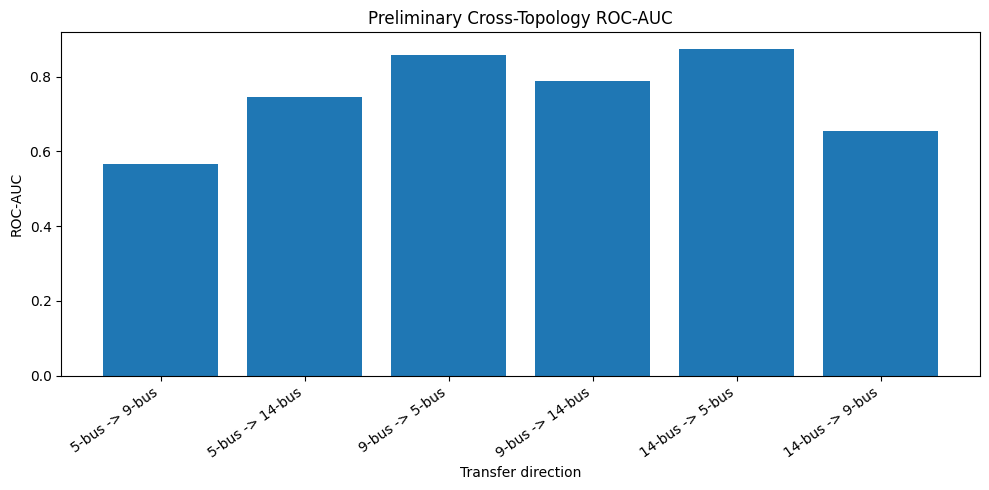

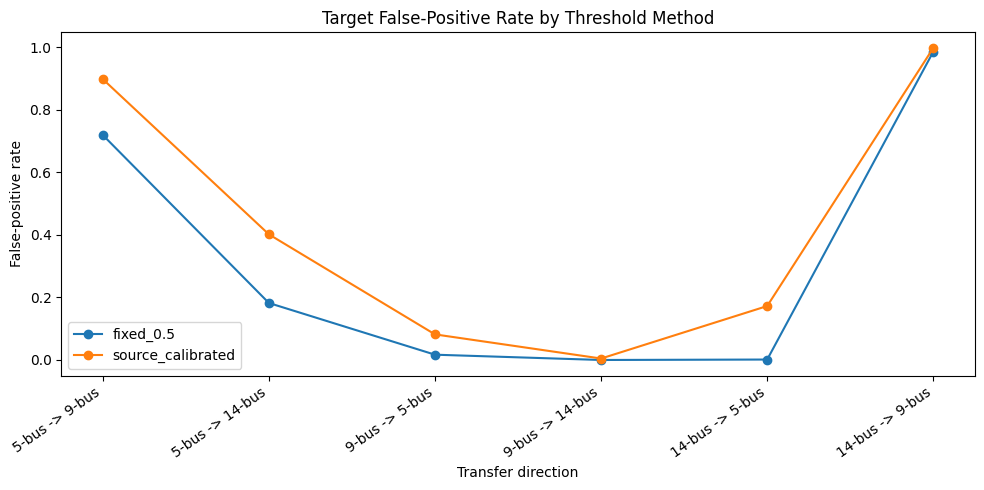

Package created: /content/FDIA_Preliminary_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files

OUT = "/content/fdia_final_results"

# Load the saved preliminary results
results = pd.read_csv(f"{OUT}/preliminary_fast_results.csv")

# Compact table for comparing the two thresholds
summary = results[
    [
        "source", "target", "features", "threshold_method",
        "balanced_accuracy", "precision", "recall",
        "f1", "fpr", "roc_auc", "pr_auc"
    ]
].copy()

summary = summary.round(4)
summary.to_csv(f"{OUT}/preliminary_summary.csv", index=False)

print("PRELIMINARY RESULTS SUMMARY")
display(summary)

# Plot 1: ROC-AUC by transfer direction
plot_data = results.drop_duplicates(
    subset=["source", "target"]
).copy()

plot_data["transfer"] = (
    plot_data["source"] + " -> " + plot_data["target"]
)

plt.figure(figsize=(10, 5))
plt.bar(plot_data["transfer"], plot_data["roc_auc"])
plt.ylabel("ROC-AUC")
plt.xlabel("Transfer direction")
plt.title("Preliminary Cross-Topology ROC-AUC")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(f"{OUT}/roc_auc_comparison.png", dpi=200)
plt.show()

# Plot 2: FPR for both threshold methods
plt.figure(figsize=(10, 5))
for method, group in results.groupby("threshold_method"):
    labels = group["source"] + " -> " + group["target"]
    plt.plot(labels, group["fpr"], marker="o", label=method)

plt.ylabel("False-positive rate")
plt.xlabel("Transfer direction")
plt.title("Target False-Positive Rate by Threshold Method")
plt.xticks(rotation=35, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/fpr_comparison.png", dpi=200)
plt.show()

# Package all saved outputs
zip_path = "/content/FDIA_Preliminary_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, names in os.walk(OUT):
        for name in names:
            path = os.path.join(root, name)
            z.write(path, arcname=os.path.relpath(path, OUT))

print("Package created:", zip_path)
files.download(zip_path)


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

results_path = "/content/fdia_final_results/preliminary_fast_results.csv"
results = pd.read_csv(results_path)

print("1. RESULT COMPLETENESS")
print("Total result rows:", len(results))
print("Transfer directions:", results[["source", "target"]].drop_duplicates().shape[0])
print("Threshold methods:", results["threshold_method"].unique().tolist())

print("\n2. CHECK FOR MISSING METRICS")
metrics = [
    "balanced_accuracy", "precision", "recall",
    "f1", "fpr", "roc_auc", "pr_auc"
]
print(results[metrics].isna().sum())

print("\n3. CHECK METRIC RANGES")
for col in metrics:
    print(f"{col}: min={results[col].min():.4f}, max={results[col].max():.4f}")

print("\n4. TRANSFER SUMMARY")
display(
    results[
        ["source", "target", "features", "threshold_method",
         "balanced_accuracy", "recall", "fpr", "roc_auc", "pr_auc"]
    ].round(4)
)

print("\n5. CHECK WHETHER BOTH THRESHOLD METHODS HAVE IDENTICAL AUC")
auc_check = results.groupby(["source", "target"])[
    ["roc_auc", "pr_auc"]
].nunique()
print("Pairs where AUC differs by threshold method:")
display(auc_check[(auc_check > 1).any(axis=1)])

print("\nInitial checks complete. These checks do not prove absence of data leakage.")


1. RESULT COMPLETENESS
Total result rows: 12
Transfer directions: 6
Threshold methods: ['fixed_0.5', 'source_calibrated']

2. CHECK FOR MISSING METRICS
balanced_accuracy    0
precision            0
recall               0
f1                   0
fpr                  0
roc_auc              0
pr_auc               0
dtype: int64

3. CHECK METRIC RANGES
balanced_accuracy: min=0.5005, max=0.8766
precision: min=0.6004, max=1.0000
recall: min=0.5658, max=0.9996
f1: min=0.6945, max=0.8597
fpr: min=0.0000, max=0.9986
roc_auc: min=0.5660, max=0.8748
pr_auc: min=0.6486, max=0.9367

4. TRANSFER SUMMARY


,source,target,features,threshold_method,balanced_accuracy,recall,fpr,roc_auc,pr_auc
0,5-bus,9-bus,20,fixed_0.5,0.5349,0.7897,0.7198,0.5660,0.6486
1,5-bus,9-bus,20,source_calibrated,0.5120,0.9228,0.8988,0.5660,0.6486
2,5-bus,14-bus,28,fixed_0.5,0.7070,0.5963,0.1823,0.7453,0.8521
3,5-bus,14-bus,28,source_calibrated,0.6510,0.7041,0.4020,0.7453,0.8521
4,9-bus,5-bus,20,fixed_0.5,0.8546,0.7261,0.0169,0.8591,0.9279
5,9-bus,5-bus,20,source_calibrated,0.8303,0.7424,0.0819,0.8591,0.9279
6,9-bus,14-bus,44,fixed_0.5,0.7829,0.5658,0.0000,0.7871,0.8850
7,9-bus,14-bus,44,source_calibrated,0.7823,0.5692,0.0047,0.7871,0.8850
8,14-bus,5-bus,28,fixed_0.5,0.8766,0.7547,0.0014,0.8748,0.9367
9,14-bus,5-bus,28,source_calibrated,0.8097,0.7920,0.1726,0.8748,0.9367



5. CHECK WHETHER BOTH THRESHOLD METHODS HAVE IDENTICAL AUC
Pairs where AUC differs by threshold method:


,,roc_auc,pr_auc
source,target,,



Initial checks complete. These checks do not prove absence of data leakage.


In [ ]:

import pandas as pd
import numpy as np

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)
    print("\n" + "=" * 45)
    print(topology)

    print("Rows:", len(df))
    print("Timestamp column exists:", "Timestamp" in df.columns)

    if "Timestamp" in df.columns:
        ts = pd.to_datetime(df["Timestamp"], errors="coerce")
        print("Valid timestamps:", int(ts.notna().sum()))
        print("Unique timestamps:", int(ts.nunique()))
        print("Repeated timestamps:", int(ts.duplicated().sum()))
        print("Timestamp examples:", df["Timestamp"].head(3).tolist())

    # Check repeated measurement rows without timestamp/label.
    X = df.drop(
        columns=["Timestamp", "label_multi"],
        errors="ignore"
    )
    X = X.select_dtypes(include=np.number)

    print("Exact duplicate measurement rows:", int(X.duplicated().sum()))
    print("Feature count:", X.shape[1])



5-bus
Rows: 500000
Timestamp column exists: True


/tmp/ipykernel_1250/2994979014.py:19: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(df["Timestamp"], errors="coerce")


Valid timestamps: 500000
Unique timestamps: 500000
Repeated timestamps: 0
Timestamp examples: ['29/09/2025 20:01', '29/09/2025 20:02', '29/09/2025 20:03']
Exact duplicate measurement rows: 0
Feature count: 36


ParserError: Error tokenizing data. C error: Expected 70 fields in line 285893, saw 82


In [ ]:
import pandas as pd
import numpy as np

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)

    print("\n" + "=" * 45)
    print(topology)
    print("Rows:", len(df))

    if "Timestamp" in df.columns:
        ts = pd.to_datetime(df["Timestamp"], errors="coerce")
        print("Valid timestamps:", int(ts.notna().sum()))
        print("Unique timestamps:", int(ts.nunique()))
        print("Repeated timestamps:", int(ts.duplicated().sum()))

    X = df.drop(
        columns=["Timestamp", "label_multi"],
        errors="ignore"
    )
    X = X.select_dtypes(include=np.number)

    print("Exact duplicate measurement rows:",
          int(X.duplicated().sum()))
    print("Feature count:", X.shape[1])


5-bus
Rows: 500000


/tmp/ipykernel_1250/182571511.py:18: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  ts = pd.to_datetime(df["Timestamp"], errors="coerce")


Valid timestamps: 500000
Unique timestamps: 500000
Repeated timestamps: 0
Exact duplicate measurement rows: 0
Feature count: 36


ParserError: Error tokenizing data. C error: Expected 70 fields in line 285893, saw 82


In [ ]:
filename = "measurements_9bus_multi.csv"
bad_line = 258593

with open(filename, "r", encoding="utf-8", errors="replace") as f:
    for line_number, line in enumerate(f, start=1):
        if bad_line - 2 <= line_number <= bad_line + 2:
            print(f"\nLine {line_number}:")
            print(line[:1000])


Line 258591:
28/03/2026 9:41,-0.000848391,0.131305398,-0.025744886,-0.017368658,-0.052482934,0.090501726,-0.04129626,-0.03950612,0.026138888,0.040185845,-0.044930361,0.131483671,-0.156394793,-0.01070545,0.145910054,-0.171799943,0.065019818,-0.020422091,0.019696102,3.428121212,0.539464151,0.150536252,0.21586081,-0.039055854,-0.078940999,0.008429615,0.036730442,0.038423519,0.040237876,0.05614059,-5.771006871,0.497066177,-0.333498264,0.087035067,0.000652173,-0.057136591,0.034945046,-0.000535428,-0.147577643,0.232524811,-0.041349169,0.001418778,-0.004056368,0.040728461,0.00402291,-0.05889517,0.090801291,-0.183215837,0.381356825,-0.274549946,-0.004273553,-0.003602761,0.008780734,-4.992378787,-4.9921705,-4.97421672,-0.046929642,0.015063521,-5.040690894,-4.991649287,-0.014628396,-0.000552173,0.011400601,-9.44E-05,-4.991294939,-0.073576332,0.020724712,-4.95020593,0


Line 258592:
28/03/2026 9:42,0.005247799,0.019957851,-1.198925501,-0.067830197,-0.282060288,0.094432193,0.01426571,0.034251677,

In [ ]:
filename = "measurements_9bus_multi.csv"

with open(filename, "r", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

print("Header columns:", len(lines[0].rstrip("\n").split(",")))

for line_number in range(258590, 258597):
    row = lines[line_number - 1].rstrip("\n").split(",")
    print(f"Line {line_number}: {len(row)} fields")

Header columns: 70
Line 258590: 70 fields
Line 258591: 70 fields
Line 258592: 70 fields
Line 258593: 70 fields
Line 258594: 70 fields
Line 258595: 70 fields
Line 258596: 70 fields


In [ ]:
import pandas as pd

filename = "measurements_9bus_multi.csv"

try:
    df_test = pd.read_csv(filename, engine="python")
    print("CSV loaded successfully!")
    print("Shape:", df_test.shape)
    print("Columns:", len(df_test.columns))
except Exception as e:
    print("Error:", repr(e))

Error: ParserError('Expected 70 fields in line 285893, saw 82')


In [ ]:
from collections import Counter

filename = "measurements_9bus_multi.csv"

with open(filename, "r", encoding="utf-8-sig", errors="replace") as f:
    header = f.readline()
    expected_fields = len(header.rstrip("\r\n").split(","))

    bad_rows = []
    total_rows = 0
    field_counts = Counter()

    for line_number, line in enumerate(f, start=2):
        total_rows += 1
        field_count = len(line.rstrip("\r\n").split(","))
        field_counts[field_count] += 1

        if field_count != expected_fields:
            bad_rows.append((line_number, field_count, line[:250]))

print("Expected fields:", expected_fields)
print("Total data rows:", total_rows)
print("Field-count distribution:", dict(field_counts))
print("Number of malformed rows:", len(bad_rows))

print("\nFirst 20 malformed rows:")
for line_number, count, preview in bad_rows[:20]:
    print(f"\nLine {line_number}: {count} fields")
    print(preview)

Expected fields: 70
Total data rows: 501217
Field-count distribution: {70: 501216, 82: 1}
Number of malformed rows: 1

First 20 malformed rows:

Line 285893: 82 fields
16/04/2026 8:43,0.021418405,-0.014621133,-5.021589267,-5.010680683,-5.045128035,-0.123448935,-0.027692113,0.055739338,0.013363562,0.028534522,-0.023670543,-0.035030327,-0.003752649,-5.014514885,-0.077827053,0.151369504,-0.0448191,0.000948758,-0.07673


In [ ]:
filename = "measurements_9bus_multi.csv"

with open(filename, "r", encoding="utf-8-sig", errors="replace") as f:
    lines = f.readlines()

header = lines[0].rstrip("\r\n").split(",")
bad_line_number = 285893
bad_row = lines[bad_line_number - 1].rstrip("\r\n").split(",")

print("Expected fields:", len(header))
print("Actual fields:", len(bad_row))

print("\nLast 20 fields in the malformed row:")
start = max(0, len(bad_row) - 20)

for i in range(start, len(bad_row)):
    print(f"Field {i + 1}: {bad_row[i]}")

print("\nHeader names and values for the first 70 fields:")
for i, (name, value) in enumerate(zip(header, bad_row[:70]), start=1):
    print(f"{i}. {name} = {value}")

Expected fields: 70
Actual fields: 82

Last 20 fields in the malformed row:
Field 63: 0.35697671
Field 64: 0.011289827
Field 65: -0.007909033
Field 66: 0.106825621
Field 67: -0.027624156
Field 68: 0.000134308
Field 69: 0.100197894
Field 70: -0.311171218
Field 71: 0.029954496
Field 72: 0.109876563
Field 73: -0.013203075
Field 74: -0.029802816
Field 75: 0.011812428
Field 76: 0.114505483
Field 77: -0.136269151
Field 78: 0.130539475
Field 79: -0.411327645
Field 80: 0.449088531
Field 81: -0.121749142
Field 82: 2

Header names and values for the first 70 fields:
1. Timestamp = 16/04/2026 8:43
2. Flow_1_4_t-0 = 0.021418405
3. Flow_4_5_t-0 = -0.014621133
4. Flow_5_6_t-0 = -5.021589267
5. Flow_3_6_t-0 = -5.010680683
6. Flow_6_7_t-0 = -5.045128035
7. Flow_7_8_t-0 = -0.123448935
8. Flow_8_2_t-0 = -0.027692113
9. Flow_8_9_t-0 = 0.055739338
10. Flow_9_3_t-0 = 0.013363562
11. Inj_2_t-0 = 0.028534522
12. Inj_3_t-0 = -0.023670543
13. Inj_4_t-0 = -0.035030327
14. Inj_5_t-0 = -0.003752649
15. Inj_6_t-0 

In [ ]:
import csv
import pandas as pd

source_file = "measurements_9bus_multi.csv"
clean_file = "measurements_9bus_multi_clean.csv"
bad_line_number = 285893

with open(source_file, "r", encoding="utf-8-sig", newline="") as source:
    with open(clean_file, "w", encoding="utf-8", newline="") as output:
        writer = csv.writer(output)

        reader = csv.reader(source)
        header = next(reader)
        writer.writerow(header)

        skipped_rows = 0
        written_rows = 0

        for line_number, row in enumerate(reader, start=2):
            if line_number == bad_line_number:
                skipped_rows += 1
                continue

            if len(row) != len(header):
                raise ValueError(
                    f"Unexpected malformed row at line {line_number}: "
                    f"{len(row)} fields; expected {len(header)}."
                )

            writer.writerow(row)
            written_rows += 1

print("Clean file saved:", clean_file)
print("Expected columns:", len(header))
print("Rows retained:", written_rows)
print("Rows excluded:", skipped_rows)

# Verify the saved copy
df9 = pd.read_csv(clean_file)

print("Verified shape:", df9.shape)
print("Columns:", len(df9.columns))
print("Invalid label values:")
labels = pd.to_numeric(df9["label_multi"], errors="coerce")
print(sorted(labels.dropna().unique())[:35])
print("Missing labels:", int(labels.isna().sum()))

Clean file saved: measurements_9bus_multi_clean.csv
Expected columns: 70
Rows retained: 501216
Rows excluded: 1
Verified shape: (501216, 70)
Columns: 70
Invalid label values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Missing labels: 0


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi.csv"
}

summary = []

for topology, filename in files.items():
    print("\n" + "=" * 55)
    print(topology, "-", filename)

    df = pd.read_csv(filename)

    if "label_multi" not in df.columns:
        raise ValueError(f"{filename} has no label_multi column")

    labels = pd.to_numeric(df["label_multi"], errors="coerce")
    features = df.drop(
        columns=["Timestamp", "label_multi"],
        errors="ignore"
    ).select_dtypes(include=np.number)

    valid_labels = labels.notna()
    invalid_labels = labels.notna() & ~labels.between(0, 30)

    print("Shape:", df.shape)
    print("Feature count:", features.shape[1])
    print("Missing labels:", int(labels.isna().sum()))
    print("Labels outside 0–30:", int(invalid_labels.sum()))
    print("Exact duplicate feature rows:", int(features.duplicated().sum()))
    print("Unique label values:", sorted(labels.dropna().unique().tolist()))

    print("\nNormal/attack counts:")
    print("Normal (0):", int((labels == 0).sum()))
    print("Attack (1–30):", int(labels.between(1, 30).sum()))

    if "Timestamp" in df.columns:
        ts = pd.to_datetime(
            df["Timestamp"],
            dayfirst=True,
            errors="coerce"
        )
        print("Invalid timestamps:", int(ts.isna().sum()))
        print("Repeated timestamps:", int(ts.duplicated().sum()))

    summary.append({
        "topology": topology,
        "rows": len(df),
        "columns": len(df.columns),
        "features": features.shape[1],
        "missing_labels": int(labels.isna().sum()),
        "invalid_labels": int(invalid_labels.sum()),
        "normal_rows": int((labels == 0).sum()),
        "attack_rows": int(labels.between(1, 30).sum()),
        "duplicate_feature_rows": int(features.duplicated().sum())
    })

summary_df = pd.DataFrame(summary)

print("\n\nFINAL AUDIT SUMMARY")
display(summary_df)

summary_df.to_csv(
    "/content/fdia_final_results/dataset_audit.csv",
    index=False
)

print("Saved audit to /content/fdia_final_results/dataset_audit.csv")



5-bus - measurements_5bus_multi.csv
Shape: (500000, 38)
Feature count: 36
Missing labels: 0
Labels outside 0–30: 0
Exact duplicate feature rows: 0
Unique label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

Normal/attack counts:
Normal (0): 200650
Attack (1–30): 299350
Invalid timestamps: 0
Repeated timestamps: 0

9-bus - measurements_9bus_multi_clean.csv
Shape: (501216, 70)
Feature count: 68
Missing labels: 0
Labels outside 0–30: 0
Exact duplicate feature rows: 1216
Unique label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]

Normal/attack counts:
Normal (0): 200556
Attack (1–30): 300660
Invalid timestamps: 0
Repeated timestamps: 1216

14-bus - measurements_14bus_multi.csv


ParserError: Error tokenizing data. C error: Expected 134 fields in line 144721, saw 153


In [ ]:
filename = "measurements_14bus_multi.csv"

with open(filename, "r", encoding="utf-8-sig", errors="replace") as f:
    header = f.readline()
    expected_fields = len(header.rstrip("\r\n").split(","))

    bad_rows = []
    total_rows = 0

    for line_number, line in enumerate(f, start=2):
        total_rows += 1
        field_count = len(line.rstrip("\r\n").split(","))

        if field_count != expected_fields:
            bad_rows.append((line_number, field_count, line[:250]))

print("Expected fields:", expected_fields)
print("Total data rows:", total_rows)
print("Malformed rows:", len(bad_rows))

for line_number, count, preview in bad_rows[:20]:
    print(f"\nLine {line_number}: {count} fields")
    print(preview)

Expected fields: 134
Total data rows: 500635
Malformed rows: 1

Line 144721: 153 fields
8/01/2026 8:18,-0.015391527,-4.46E-05,0.004592902,-447.1929908,0.005633911,-447.1984113,-447.2043543,-447.2035557,-447.199411,0.004339321,-0.009027952,0.001809006,-0.005367606,0.006736757,0.010311028,0.00320167,0.003002721,-0.009991162,-0.001181614,0


In [ ]:
import csv
import pandas as pd
import numpy as np

def clean_csv(source_file, output_file, bad_line_number):
    with open(source_file, "r", encoding="utf-8-sig", newline="") as src:
        reader = csv.reader(src)
        header = next(reader)

        written = 0
        skipped = 0

        with open(output_file, "w", encoding="utf-8", newline="") as dst:
            writer = csv.writer(dst)
            writer.writerow(header)

            for line_number, row in enumerate(reader, start=2):
                if line_number == bad_line_number:
                    skipped += 1
                    continue

                if len(row) != len(header):
                    raise ValueError(
                        f"Unexpected malformed row at line {line_number}"
                    )

                writer.writerow(row)
                written += 1

    print(f"\nCreated: {output_file}")
    print(f"Rows retained: {written}; rows excluded: {skipped}")

clean_csv(
    "measurements_14bus_multi.csv",
    "measurements_14bus_multi_clean.csv",
    144721
)

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi_clean.csv"
}

results = []

for topology, filename in files.items():
    df = pd.read_csv(filename)

    labels = pd.to_numeric(df["label_multi"], errors="coerce")
    X = df.drop(
        columns=["Timestamp", "label_multi"],
        errors="ignore"
    ).select_dtypes(include=np.number)

    invalid = labels.isna() | ~labels.between(0, 30)

    row = {
        "topology": topology,
        "rows": len(df),
        "columns": len(df.columns),
        "features": X.shape[1],
        "missing_labels": int(labels.isna().sum()),
        "invalid_labels": int(invalid.sum()),
        "normal_rows": int((labels == 0).sum()),
        "attack_rows": int(labels.between(1, 30).sum()),
        "duplicate_feature_rows": int(X.duplicated().sum())
    }

    if "Timestamp" in df.columns:
        ts = pd.to_datetime(
            df["Timestamp"], dayfirst=True, errors="coerce"
        )
        row["invalid_timestamps"] = int(ts.isna().sum())
        row["repeated_timestamps"] = int(ts.duplicated().sum())

    results.append(row)

audit = pd.DataFrame(results)
display(audit)

audit.to_csv("/content/dataset_audit.csv", index=False)
print("Saved audit: /content/dataset_audit.csv")


Created: measurements_14bus_multi_clean.csv
Rows retained: 500634; rows excluded: 1


,topology,rows,columns,features,missing_labels,invalid_labels,normal_rows,attack_rows,duplicate_feature_rows,invalid_timestamps,repeated_timestamps
0,5-bus,500000,38,36,0,0,200650,299350,0,0,0
1,9-bus,501216,70,68,0,0,200556,300660,1216,0,1216
2,14-bus,500634,134,132,0,0,200575,300059,634,0,634


Saved audit: /content/dataset_audit.csv


In [ ]:
import pandas as pd

files = {
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi_clean.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)

    print("\n" + "=" * 55)
    print(topology)

    # Count timestamps appearing more than once
    duplicated_ts = df[df.duplicated("Timestamp", keep=False)]

    print("Rows with repeated timestamps:", len(duplicated_ts))
    print(
        "Unique repeated timestamps:",
        duplicated_ts["Timestamp"].nunique()
    )

    # Check if repeated timestamps have identical features AND labels
    compare_cols = [
        c for c in df.columns
        if c != "Timestamp"
    ]

    exact_repeats = df.duplicated(
        subset=["Timestamp"] + compare_cols,
        keep=False
    )

    print("Rows belonging to exact repeated records:",
          int(exact_repeats.sum()))

    # Show a few examples
    print("\nFirst repeated timestamp examples:")
    print(
        duplicated_ts[
            ["Timestamp", "label_multi"]
        ].head(10).to_string(index=False)
    )


9-bus
Rows with repeated timestamps: 2432
Unique repeated timestamps: 1216
Rows belonging to exact repeated records: 2432

First repeated timestamp examples:
       Timestamp  label_multi
15/04/2026 12:27            0
15/04/2026 12:28            0
15/04/2026 12:29           17
15/04/2026 12:30            0
15/04/2026 12:31            0
15/04/2026 12:32           13
15/04/2026 12:33           15
15/04/2026 12:34            0
15/04/2026 12:35            0
15/04/2026 12:36           12

14-bus
Rows with repeated timestamps: 1268
Unique repeated timestamps: 634
Rows belonging to exact repeated records: 1268

First repeated timestamp examples:
      Timestamp  label_multi
7/01/2026 21:44            0
7/01/2026 21:45           29
7/01/2026 21:46            0
7/01/2026 21:47           16
7/01/2026 21:48            0
7/01/2026 21:49           25
7/01/2026 21:50            2
7/01/2026 21:51            0
7/01/2026 21:52           27
7/01/2026 21:53            0


In [ ]:
import pandas as pd

files = {
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi_clean.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)

    print("\n" + "=" * 55)
    print(topology)

    # Find all rows identical across every column
    duplicate_mask = df.duplicated(keep=False)
    duplicate_rows = df.loc[duplicate_mask].copy()

    print("Rows involved in exact duplicates:", len(duplicate_rows))

    # Show original row positions for a few duplicates
    duplicated_indices = df.index[df.duplicated(keep=False)]

    print("\nFirst 20 duplicate row positions (0-based):")
    print(sorted(duplicated_indices.tolist())[:20])

    # Check gaps between duplicate row positions
    positions = sorted(duplicated_indices.tolist())
    if len(positions) > 1:
        gaps = pd.Series(positions).diff().dropna()
        print("\nMost common gaps between duplicate positions:")
        print(gaps.value_counts().head(10))

    # Display a few duplicated records
    print("\nExample duplicated records:")
    print(duplicate_rows.head(4).to_string(index=False))


9-bus
Rows involved in exact duplicates: 2432

First 20 duplicate row positions (0-based):
[284675, 284676, 284677, 284678, 284679, 284680, 284681, 284682, 284683, 284684, 284685, 284686, 284687, 284688, 284689, 284690, 284691, 284692, 284693, 284694]

Most common gaps between duplicate positions:
1.0    2431
Name: count, dtype: int64

Example duplicated records:
       Timestamp  Flow_1_4_t-0  Flow_4_5_t-0  Flow_5_6_t-0  Flow_3_6_t-0  Flow_6_7_t-0  Flow_7_8_t-0  Flow_8_2_t-0  Flow_8_9_t-0  Flow_9_3_t-0  Inj_2_t-0  Inj_3_t-0  Inj_4_t-0  Inj_5_t-0    Inj_6_t-0  Inj_7_t-0  Inj_8_t-0  Inj_9_t-0  Flow_1_4_t-1  Flow_4_5_t-1  Flow_5_6_t-1  Flow_3_6_t-1  Flow_6_7_t-1  Flow_7_8_t-1  Flow_8_2_t-1  Flow_8_9_t-1  Flow_9_3_t-1  Inj_2_t-1  Inj_3_t-1  Inj_4_t-1  Inj_5_t-1    Inj_6_t-1   Inj_7_t-1  Inj_8_t-1   Inj_9_t-1  Flow_1_4_t-2  Flow_4_5_t-2  Flow_5_6_t-2  Flow_3_6_t-2  Flow_6_7_t-2  Flow_7_8_t-2  Flow_8_2_t-2  Flow_8_9_t-2  Flow_9_3_t-2  Inj_2_t-2  Inj_3_t-2  Inj_4_t-2  Inj_5_t-2  Inj_6_t-2  

In [ ]:
import pandas as pd

files = {
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi_clean.csv"
}

for topology, filename in files.items():
    df = pd.read_csv(filename)

    print("\n" + "=" * 55)
    print(topology)

    # Identify rows repeated anywhere earlier in the dataset
    duplicated = df.duplicated(keep="first")
    positions = df.index[duplicated].tolist()

    print("Rows that duplicate an earlier row:", len(positions))

    if positions:
        print("First duplicate position:", positions[0])
        print("Last duplicate position:", positions[-1])

        # Inspect a window around the start of the duplicate section
        start = max(0, positions[0] - 3)
        end = min(len(df), positions[0] + 8)

        print("\nRows around the first duplicate:")
        display(df.iloc[start:end, :4])

        # Compare timestamp ordering
        ts = pd.to_datetime(
            df["Timestamp"], dayfirst=True, errors="coerce"
        )
        print(
            "\nTimestamp sequence around that position:"
        )
        print(ts.iloc[start:end].to_string())


9-bus
Rows that duplicate an earlier row: 1216
First duplicate position: 285891
Last duplicate position: 287106

Rows around the first duplicate:


,Timestamp,Flow_1_4_t-0,Flow_4_5_t-0,Flow_5_6_t-0
285888,16/04/2026 8:40,0.041450,-0.126758,0.369405
285889,16/04/2026 8:41,-0.030292,0.064674,-0.034505
285890,16/04/2026 8:42,0.000949,-0.076738,0.041579
285891,15/04/2026 12:27,0.020526,-0.094216,0.002796
285892,15/04/2026 12:28,0.004645,0.004559,-0.023400
285893,15/04/2026 12:29,0.013118,0.041130,-1846.848362
285894,15/04/2026 12:30,-0.010442,0.002926,0.038126
285895,15/04/2026 12:31,0.015175,-0.035165,-0.026210
285896,15/04/2026 12:32,-9.965350,-10.048658,-10.021753
285897,15/04/2026 12:33,0.003981,-0.013908,-0.005783



Timestamp sequence around that position:
285888   2026-04-16 08:40:00
285889   2026-04-16 08:41:00
285890   2026-04-16 08:42:00
285891   2026-04-15 12:27:00
285892   2026-04-15 12:28:00
285893   2026-04-15 12:29:00
285894   2026-04-15 12:30:00
285895   2026-04-15 12:31:00
285896   2026-04-15 12:32:00
285897   2026-04-15 12:33:00
285898   2026-04-15 12:34:00

14-bus
Rows that duplicate an earlier row: 634
First duplicate position: 144719
Last duplicate position: 145352

Rows around the first duplicate:


,Timestamp,Flow_1_2_t-0,Flow_1_5_t-0,Flow_2_3_t-0
144716,8/01/2026 8:15,-0.001448,0.005999,-0.006532
144717,8/01/2026 8:16,-0.007075,0.001778,-0.000142
144718,8/01/2026 8:17,0.004253,0.003390,0.000298
144719,7/01/2026 21:44,0.003570,0.002024,0.002465
144720,7/01/2026 21:45,0.002177,0.004568,-0.000407
144721,7/01/2026 21:46,0.021701,0.000739,-0.003809
144722,7/01/2026 21:47,-0.015349,-0.006887,0.012294
144723,7/01/2026 21:48,0.015842,0.004665,-0.011171
144724,7/01/2026 21:49,-0.028861,0.001740,0.005342
144725,7/01/2026 21:50,440.928897,-0.004812,440.917421



Timestamp sequence around that position:
144716   2026-01-08 08:15:00
144717   2026-01-08 08:16:00
144718   2026-01-08 08:17:00
144719   2026-01-07 21:44:00
144720   2026-01-07 21:45:00
144721   2026-01-07 21:46:00
144722   2026-01-07 21:47:00
144723   2026-01-07 21:48:00
144724   2026-01-07 21:49:00
144725   2026-01-07 21:50:00
144726   2026-01-07 21:51:00


In [ ]:
import pandas as pd

cases = [
    {
        "name": "9-bus",
        "file": "measurements_9bus_multi_clean.csv",
        "start": 285891,
        "length": 1216
    },
    {
        "name": "14-bus",
        "file": "measurements_14bus_multi_clean.csv",
        "start": 144719,
        "length": 634
    }
]

for case in cases:
    df = pd.read_csv(case["file"])

    start = case["start"]
    length = case["length"]

    # These are zero-based row positions from the earlier output.
    block = df.iloc[start:start + length].reset_index(drop=True)
    earlier = df.iloc[:start].reset_index(drop=True)

    print("\n" + "=" * 60)
    print(case["name"])
    print("Block length:", len(block))

    # Search for a contiguous exact match in the earlier data.
    matches = []

    block_values = block.astype(str).to_numpy()
    earlier_values = earlier.astype(str).to_numpy()

    for candidate in range(len(earlier) - length + 1):
        if (earlier_values[candidate] == block_values[0]).all():
            if (
                earlier_values[candidate:candidate + length]
                == block_values
            ).all():
                matches.append(candidate)

    print("Earlier exact block matches:", matches)

    if matches:
        for pos in matches:
            print(
                "Original timestamp range:",
                df.iloc[pos]["Timestamp"],
                "to",
                df.iloc[pos + length - 1]["Timestamp"]
            )
    else:
        print(
            "No full contiguous exact match found before the block. "
            "Do not remove the block yet."
        )


9-bus
Block length: 1216
Earlier exact block matches: [284675]
Original timestamp range: 15/04/2026 12:27 to 16/04/2026 8:42

14-bus
Block length: 634
Earlier exact block matches: [144085]
Original timestamp range: 7/01/2026 21:44 to 8/01/2026 8:17


In [ ]:

import pandas as pd
import os

files = {
    "5-bus": "measurements_5bus_multi.csv",
    "9-bus": "measurements_9bus_multi_clean.csv",
    "14-bus": "measurements_14bus_multi_clean.csv"
}

# Verified duplicate blocks: zero-based start position and length
duplicate_blocks = {
    "5-bus": None,
    "9-bus": (285891, 1216),
    "14-bus": (144719, 634)
}

output_dir = "/content/fdia_final_results"
os.makedirs(output_dir, exist_ok=True)

report = []

for topology, filename in files.items():
    print(f"\nCleaning {topology}...")

    df = pd.read_csv(filename)
    rows_before = len(df)

    block = duplicate_blocks[topology]
    rows_removed = 0

    if block is not None:
        start, length = block

        # Remove only the verified repeated block
        df = df.drop(df.index[start:start + length])
        rows_removed = length

    # Validate labels before saving
    if "label_multi" not in df.columns:
        raise ValueError(f"{topology}: label_multi column missing")

    df["label_multi"] = pd.to_numeric(
        df["label_multi"], errors="raise"
    )

    if df["label_multi"].isna().any():
        raise ValueError(f"{topology}: missing labels remain")

    if not df["label_multi"].isin(range(31)).all():
        raise ValueError(f"{topology}: unexpected label values")

    # Save final dataset
    output_file = os.path.join(
        output_dir, f"measurements_{topology.replace('-', '')}_final.csv"
    )
    df.to_csv(output_file, index=False)

    report.append({
        "topology": topology,
        "rows_before": rows_before,
        "duplicate_rows_removed": rows_removed,
        "rows_after": len(df),
        "columns": len(df.columns),
        "missing_labels": int(df["label_multi"].isna().sum()),
        "normal_rows": int((df["label_multi"] == 0).sum()),
        "attack_rows": int((df["label_multi"] != 0).sum()),
        "remaining_exact_duplicate_rows": int(
            df.drop(columns=["Timestamp"], errors="ignore")
              .duplicated().sum()
        ),
        "output_file": output_file
    })

report_df = pd.DataFrame(report)
report_path = os.path.join(output_dir, "final_cleaning_report.csv")
report_df.to_csv(report_path, index=False)

print("\nFINAL CLEANING REPORT")
display(report_df)

print("\nSaved report:", report_path)
print("Original CSV files were not overwritten.")



Cleaning 5-bus...

Cleaning 9-bus...

Cleaning 14-bus...

FINAL CLEANING REPORT


,topology,rows_before,duplicate_rows_removed,rows_after,columns,missing_labels,normal_rows,attack_rows,remaining_exact_duplicate_rows,output_file
0,5-bus,500000,0,500000,38,0,200650,299350,0,/content/fdia_final_results/measurements_5bus_...
1,9-bus,501216,1216,500000,70,0,200071,299929,0,/content/fdia_final_results/measurements_9bus_...
2,14-bus,500634,634,500000,134,0,200315,299685,0,/content/fdia_final_results/measurements_14bus...



Saved report: /content/fdia_final_results/final_cleaning_report.csv
Original CSV files were not overwritten.


In [ ]:

import os
import pandas as pd

DATA_DIR = "/content/fdia_final_results"

files = {
    "5-bus": os.path.join(DATA_DIR, "measurements_5bus_final.csv"),
    "9-bus": os.path.join(DATA_DIR, "measurements_9bus_final.csv"),
    "14-bus": os.path.join(DATA_DIR, "measurements_14bus_final.csv")
}

for topology, path in files.items():
    if not os.path.exists(path):
        print(f"❌ Missing: {path}")
    else:
        df = pd.read_csv(path)
        print(f"✅ {topology}: {df.shape}")
        print("   Label column exists:", "label_multi" in df.columns)


✅ 5-bus: (500000, 38)
   Label column exists: True
✅ 9-bus: (500000, 70)
   Label column exists: True
✅ 14-bus: (500000, 134)
   Label column exists: True


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)
import pandas as pd
import numpy as np
import os
import time
import gc

# =========================================================
# 1. Load the FINAL cleaned datasets explicitly
# =========================================================
OUT = "/content/fdia_final_results"
os.makedirs(OUT, exist_ok=True)

paths = {
    "5-bus": f"{OUT}/measurements_5bus_final.csv",
    "9-bus": f"{OUT}/measurements_9bus_final.csv",
    "14-bus": f"{OUT}/measurements_14bus_final.csv"
}

data_final = {}

for topology, path in paths.items():
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing final dataset: {path}")

    df = pd.read_csv(path)

    if "label_multi" not in df.columns:
        raise ValueError(f"{topology}: label_multi is missing")

    # Binary classification: 0 = normal, 1 = any attack
    y = (pd.to_numeric(df["label_multi"]) != 0).astype("int8")

    # Timestamp and label must not be model features
    X = df.drop(columns=["Timestamp", "label_multi"],
                errors="ignore")
    X = X.select_dtypes(include=np.number)

    data_final[topology] = (X, y)

    print(
        f"Loaded {topology}: rows={len(df):,}, "
        f"features={X.shape[1]}, "
        f"normal={(y == 0).sum():,}, attacks={(y == 1).sum():,}"
    )

    del df
    gc.collect()

# =========================================================
# 2. Run all six cross-topology transfer experiments
# =========================================================
directions = [
    ("5-bus", "9-bus"),
    ("5-bus", "14-bus"),
    ("9-bus", "5-bus"),
    ("9-bus", "14-bus"),
    ("14-bus", "5-bus"),
    ("14-bus", "9-bus")
]

results = []
start_time = time.time()

for run_number, (source, target) in enumerate(directions, start=1):
    Xs, ys = data_final[source]
    Xt, yt = data_final[target]

    # Use only identically named numeric features
    common = sorted(set(Xs.columns) & set(Xt.columns))

    if not common:
        raise ValueError(f"No shared features for {source} -> {target}")

    X_source = Xs[common]
    X_target = Xt[common]

    X_train, X_val, y_train, y_val = train_test_split(
        X_source,
        ys,
        test_size=0.2,
        stratify=ys,
        random_state=42
    )

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=80,
            max_depth=20,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )

    print(
        f"\n[{run_number}/6] Training {source} -> {target}; "
        f"shared features={len(common)}",
        flush=True
    )

    model.fit(X_train, y_train)

    # Calibrate threshold using source validation normals only
    val_scores = model.predict_proba(X_val)[:, 1]
    normal_val_scores = val_scores[
        y_val.to_numpy() == 0
    ]

    if len(normal_val_scores) == 0:
        raise ValueError("No normal samples in source validation set")

    calibrated_threshold = float(
        np.quantile(normal_val_scores, 0.95)
    )

    # Target labels are used only for evaluation
    target_scores = model.predict_proba(X_target)[:, 1]
    target_labels = yt.to_numpy()

    for method, threshold in [
        ("fixed_0.5", 0.5),
        ("source_calibrated", calibrated_threshold)
    ]:
        pred = (target_scores >= threshold).astype("int8")

        tn, fp, fn, tp = confusion_matrix(
            target_labels, pred, labels=[0, 1]
        ).ravel()

        results.append({
            "source": source,
            "target": target,
            "features": len(common),
            "threshold_method": method,
            "threshold": threshold,
            "accuracy": accuracy_score(target_labels, pred),
            "balanced_accuracy": balanced_accuracy_score(
                target_labels, pred
            ),
            "precision": precision_score(
                target_labels, pred, zero_division=0
            ),
            "recall": recall_score(
                target_labels, pred, zero_division=0
            ),
            "f1": f1_score(
                target_labels, pred, zero_division=0
            ),
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "fpr": fp / (fp + tn) if fp + tn else np.nan,
            "roc_auc": roc_auc_score(target_labels, target_scores),
            "pr_auc": average_precision_score(
                target_labels, target_scores
            ),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp)
        })

    # Save progress after each completed direction
    pd.DataFrame(results).to_csv(
        f"{OUT}/final_cleaned_transfer_results.csv",
        index=False
    )

    print(
        f"Completed [{run_number}/6] {source} -> {target}",
        flush=True
    )

    del model, X_train, X_val, y_train, y_val
    del X_source, X_target, val_scores, target_scores
    gc.collect()

# =========================================================
# 3. Save and display final results
# =========================================================
final_df = pd.DataFrame(results)

final_path = f"{OUT}/final_cleaned_transfer_results.csv"
final_df.to_csv(final_path, index=False)

print("\nALL SIX TRANSFER DIRECTIONS COMPLETED")
display(final_df.round(4))

print(f"\nTotal elapsed time: {(time.time() - start_time)/60:.1f} minutes")
print("Final results saved to:", final_path)


Loaded 5-bus: rows=500,000, features=36, normal=200,650, attacks=299,350
Loaded 9-bus: rows=500,000, features=68, normal=200,071, attacks=299,929
Loaded 14-bus: rows=500,000, features=132, normal=200,315, attacks=299,685

[1/6] Training 5-bus -> 9-bus; shared features=20
Completed [1/6] 5-bus -> 9-bus

[2/6] Training 5-bus -> 14-bus; shared features=28
Completed [2/6] 5-bus -> 14-bus

[3/6] Training 9-bus -> 5-bus; shared features=20
Completed [3/6] 9-bus -> 5-bus

[4/6] Training 9-bus -> 14-bus; shared features=44
Completed [4/6] 9-bus -> 14-bus

[5/6] Training 14-bus -> 5-bus; shared features=28
Completed [5/6] 14-bus -> 5-bus

[6/6] Training 14-bus -> 9-bus; shared features=44
Completed [6/6] 14-bus -> 9-bus

ALL SIX TRANSFER DIRECTIONS COMPLETED


,source,target,features,threshold_method,threshold,accuracy,balanced_accuracy,precision,recall,f1,specificity,fpr,roc_auc,pr_auc,TN,FP,FN,TP
0,5-bus,9-bus,20,fixed_0.5,0.5000,0.5881,0.5351,0.6217,0.8002,0.6997,0.2701,0.7299,0.5704,0.6523,54047,146024,59939,239990
1,5-bus,9-bus,20,source_calibrated,0.2315,0.5964,0.5109,0.6055,0.9393,0.7363,0.0825,0.9175,0.5704,0.6523,16503,183568,18210,281719
2,5-bus,14-bus,28,fixed_0.5,0.5000,0.7302,0.7442,0.8447,0.6738,0.7496,0.8147,0.1853,0.7902,0.8757,163190,37125,97770,201915
3,5-bus,14-bus,28,source_calibrated,0.2045,0.6873,0.6648,0.7219,0.7780,0.7489,0.5517,0.4483,0.7902,0.8757,110510,89805,66539,233146
4,9-bus,5-bus,20,fixed_0.5,0.5000,0.8363,0.8631,0.9988,0.7275,0.8418,0.9987,0.0013,0.8639,0.9304,200390,260,81585,217765
5,9-bus,5-bus,20,source_calibrated,0.4434,0.8224,0.8420,0.9496,0.7427,0.8335,0.9412,0.0588,0.8639,0.9304,188855,11795,77026,222324
6,9-bus,14-bus,44,fixed_0.5,0.5000,0.8040,0.8365,1.0000,0.6730,0.8045,1.0000,0.0000,0.8403,0.9144,200315,0,97997,201688
7,9-bus,14-bus,44,source_calibrated,0.2266,0.8026,0.8337,0.9904,0.6773,0.8044,0.9902,0.0098,0.8403,0.9144,198342,1973,96711,202974
8,14-bus,5-bus,28,fixed_0.5,0.5000,0.8565,0.8801,1.0000,0.7603,0.8638,1.0000,0.0000,0.8813,0.9398,200645,5,71757,227593
9,14-bus,5-bus,28,source_calibrated,0.3012,0.8392,0.8554,0.9484,0.7736,0.8521,0.9372,0.0628,0.8813,0.9398,188050,12600,67786,231564



Total elapsed time: 42.5 minutes
Final results saved to: /content/fdia_final_results/final_cleaned_transfer_results.csv


In [ ]:
import os
import zipfile
from google.colab import files

OUT = "/content/fdia_final_results"

files_to_package = [
    "measurements_5bus_final.csv",
    "measurements_9bus_final.csv",
    "measurements_14bus_final.csv",
    "final_cleaning_report.csv",
    "final_cleaned_transfer_results.csv",
]

zip_path = "/content/FDIA_Final_Research_Files.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in files_to_package:
        path = os.path.join(OUT, filename)

        if os.path.exists(path):
            z.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("NOT FOUND:", path)

print("\nZIP created:", zip_path)
files.download(zip_path)

Added: measurements_5bus_final.csv
Added: measurements_9bus_final.csv
Added: measurements_14bus_final.csv
Added: final_cleaning_report.csv
Added: final_cleaned_transfer_results.csv

ZIP created: /content/FDIA_Final_Research_Files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd

DATA_DIR = "/content/fdia_final_results"

files = {
    "5-bus": "measurements_5bus_final.csv",
    "9-bus": "measurements_9bus_final.csv",
    "14-bus": "measurements_14bus_final.csv"
}

for topology, filename in files.items():
    path = os.path.join(DATA_DIR, filename)

    print("\n" + "=" * 45)
    print(topology)

    if not os.path.exists(path):
        print("FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Missing labels:", df["label_multi"].isna().sum())
    print("Label values:", sorted(df["label_multi"].dropna().unique()))
    print("Exact duplicate full rows:", df.duplicated().sum())

    if "Timestamp" in df.columns:
        print(
            "Repeated timestamps:",
            df["Timestamp"].duplicated().sum()
        )

    print("Normal rows:", (df["label_multi"] == 0).sum())
    print("Attack rows:", (df["label_multi"] != 0).sum())

print("\nSTEP 3 VALIDATION FINISHED")


5-bus
Shape: (500000, 38)
Missing labels: 0
Label values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Exact duplicate full rows: 0
Repeated timestamps: 0
Normal rows: 200650
Attack rows: 299350

9-bus
Shape: (500000, 70)
Missing labels: 0
Label values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(2

In [ ]:

import os
import pandas as pd

DATA_DIR = "/content/fdia_final_results"

paths = {
    "5-bus": os.path.join(DATA_DIR, "measurements_5bus_final.csv"),
    "9-bus": os.path.join(DATA_DIR, "measurements_9bus_final.csv"),
    "14-bus": os.path.join(DATA_DIR, "measurements_14bus_final.csv")
}

# Load feature names first
columns = {
    name: pd.read_csv(path, nrows=0).columns.tolist()
    for name, path in paths.items()
}

for a, b in [
    ("5-bus", "9-bus"),
    ("5-bus", "14-bus"),
    ("9-bus", "14-bus")
]:
    print("\n" + "=" * 45)
    print(f"{a} vs {b}")

    shared = sorted(
        set(columns[a]) & set(columns[b])
        - {"Timestamp", "label_multi"}
    )

    # Ensure metadata columns are excluded
    shared = [
        c for c in shared
        if c not in ("Timestamp", "label_multi")
    ]

    print("Shared feature columns:", len(shared))

    A = pd.read_csv(paths[a], usecols=shared)
    B = pd.read_csv(paths[b], usecols=shared)

    # Compare exact shared-feature rows
    A_set = set(map(tuple, A.drop_duplicates().to_numpy()))
    B_set = set(map(tuple, B.drop_duplicates().to_numpy()))

    overlap = A_set & B_set

    print("Unique shared-feature rows in", a, ":", len(A_set))
    print("Unique shared-feature rows in", b, ":", len(B_set))
    print("Exact shared-feature row overlap:", len(overlap))

print("\nSTEP 4 CHECK COMPLETE")



5-bus vs 9-bus
Shared feature columns: 20
Unique shared-feature rows in 5-bus : 500000
Unique shared-feature rows in 9-bus : 500000
Exact shared-feature row overlap: 0

5-bus vs 14-bus
Shared feature columns: 28
Unique shared-feature rows in 5-bus : 500000
Unique shared-feature rows in 14-bus : 500000
Exact shared-feature row overlap: 0

9-bus vs 14-bus
Shared feature columns: 44
Unique shared-feature rows in 9-bus : 500000
Unique shared-feature rows in 14-bus : 500000
Exact shared-feature row overlap: 0

STEP 4 CHECK COMPLETE


In [ ]:
import pandas as pd

path = "/content/fdia_final_results/final_cleaned_transfer_results.csv"

results = pd.read_csv(path)
display(results)

,source,target,features,threshold_method,threshold,accuracy,balanced_accuracy,precision,recall,f1,specificity,fpr,roc_auc,pr_auc,TN,FP,FN,TP
0,5-bus,9-bus,20,fixed_0.5,0.500000,0.588074,0.535148,0.621713,0.800156,0.699737,0.270139,0.729861,0.570423,0.652311,54047,146024,59939,239990
1,5-bus,9-bus,20,source_calibrated,0.231539,0.596444,0.510886,0.605474,0.939286,0.736312,0.082486,0.917514,0.570423,0.652311,16503,183568,18210,281719
2,5-bus,14-bus,28,fixed_0.5,0.500000,0.730210,0.744212,0.844691,0.673757,0.749603,0.814667,0.185333,0.790158,0.875709,163190,37125,97770,201915
3,5-bus,14-bus,28,source_calibrated,0.204522,0.687312,0.664826,0.721924,0.777970,0.748900,0.551681,0.448319,0.790158,0.875709,110510,89805,66539,233146
4,9-bus,5-bus,20,fixed_0.5,0.500000,0.836310,0.863082,0.998807,0.727459,0.841807,0.998704,0.001296,0.863924,0.930419,200390,260,81585,217765
5,9-bus,5-bus,20,source_calibrated,0.443440,0.822358,0.841953,0.949620,0.742689,0.833503,0.941216,0.058784,0.863924,0.930419,188855,11795,77026,222324
6,9-bus,14-bus,44,fixed_0.5,0.500000,0.804006,0.836500,1.000000,0.673000,0.804543,1.000000,0.000000,0.840329,0.914447,200315,0,97997,201688
7,9-bus,14-bus,44,source_calibrated,0.226624,0.802632,0.833721,0.990373,0.677291,0.804444,0.990151,0.009849,0.840329,0.914447,198342,1973,96711,202974
8,14-bus,5-bus,28,fixed_0.5,0.500000,0.856476,0.880133,0.999978,0.760291,0.863816,0.999975,0.000025,0.881331,0.939773,200645,5,71757,227593
9,14-bus,5-bus,28,source_calibrated,0.301242,0.839228,0.855380,0.948395,0.773556,0.852099,0.937204,0.062796,0.881331,0.939773,188050,12600,67786,231564
